# Hito 2 — Plataforma reproducible (Sala de crisis COVID-19)

**Curso:** Gestión de Datos · IN1232C · Proyecto semestral · Sala de crisis
**Alcance:** Hito 2 del proyecto semestral: descarga automatizada, unificación de los cinco esquemas de JHU, capa limpia en Parquet, identidad territorial, reglas de calidad ejecutables, almacén en estrella e integración de las fuentes externas (OWID y OxCGRT).

Este notebook **documenta y ejecuta** el Hito 2 en español: cada sección explica qué se hizo, por qué importa y con qué evidencia; después viene el código que produce esa evidencia, con **tablas y gráficos rotulados en español**.

> Los módulos que se importan son los del proyecto (`src/calidad.py`, `src/analisis_restricciones.py`): este notebook los **usa**, no los reemplaza.

> **Hitos relacionados:** `Hito 1.ipynb` (exploración inicial) y `proyecto completo.ipynb` (los tres hitos juntos).

In [1]:
# --- Preparación del entorno ------------------------------------------------
# Detecta la raíz del proyecto y agrega `src/` al path para importar los módulos
# reales del proyecto (calidad, modelos, P7, restricciones).
from datetime import date, datetime
from pathlib import Path
import sys

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Estilo de gráficos sobrio y consistente en todo el notebook.
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

raices = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
ROOT = next((p for p in raices if (p / "src").is_dir() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abre Jupyter desde la carpeta Proyecto o desde Proyecto/notebooks.")
sys.path.insert(0, str(ROOT / "src"))

# Los modulos de `src/` usan rutas relativas a la raiz del proyecto
# (por ejemplo `data/dw/covid.duckdb`), asi que se trabaja desde alli.
import os
os.chdir(ROOT)

def restaurar_backend_interactivo() -> None:
    """Vuelve al backend 'inline' del notebook.

    Los modulos de `src/` fuerzan `matplotlib.use("Agg")` al importarse, porque
    alli se guardan las figuras en disco. En el notebook hay que restaurar el
    backend interactivo o las graficas dejan de mostrarse.
    """
    import matplotlib
    matplotlib.use("module://matplotlib_inline.backend_inline")


RAW_DIR = ROOT / "data" / "raw" / "daily_reports"
CLEAN_DIR = ROOT / "data" / "clean"
DW_PATH = ROOT / "data" / "dw" / "covid.duckdb"
REPORTS_DIR = ROOT / "reports"
DOCS_DIR = ROOT / "docs"

print(f"Raíz del proyecto: {ROOT}")
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · duckdb {duckdb.__version__}")

Raíz del proyecto: C:\Users\hecto\OneDrive\Escritorio\u\gestion de datos\Proyecto
Python 3.11.9 · pandas 2.3.3 · duckdb 2.0.0


---

## 0 · Estado de las tres capas del proyecto

La arquitectura tiene **tres capas** y cada una se regenera con un script del `README.md`. Esta tabla muestra, en el estado real de este repositorio, qué existe y qué habría que reconstruir.

In [2]:
# --- Comprobación del estado de cada capa -----------------------------------
def tamano_mb(ruta: Path) -> float:
    """Tamaño en MB de un archivo o de una carpeta completa (0 si no existe)."""
    if not ruta.exists():
        return 0.0
    if ruta.is_file():
        return ruta.stat().st_size / 1024 ** 2
    return sum(p.stat().st_size for p in ruta.rglob("*") if p.is_file()) / 1024 ** 2

capas = pd.DataFrame([
    {"Capa": "1 · Crudos (data/raw)", "Contenido": "1.143 reportes diarios, 5 series, tabla UID, OWID y OxCGRT",
     "Tamaño (MB)": tamano_mb(RAW_DIR.parent), "Se regenera con": "src/descargar_reportes.py"},
    {"Capa": "2 · Limpia (data/clean)", "Contenido": "Parquet unificado + tabla de territorios",
     "Tamaño (MB)": tamano_mb(CLEAN_DIR), "Se regenera con": "src/ingesta.py · src/territorios.py"},
    {"Capa": "3 · Almacén (data/dw)", "Contenido": "Modelo estrella en DuckDB (hechos + dimensiones)",
     "Tamaño (MB)": tamano_mb(DW_PATH), "Se regenera con": "src/construir_dw.py"},
])
capas["Estado"] = np.where(capas["Tamaño (MB)"] > 0, "Disponible", "FALTA: ejecutar el script")
display(capas.style.format({"Tamaño (MB)": "{:,.1f}"}).set_caption("Estado de las tres capas del proyecto"))

,Capa,Contenido,Tamaño (MB),Se regenera con,Estado
0,1 · Crudos (data/raw),"1.143 reportes diarios, 5 series, tabla UID, OWID y OxCGRT",648.0,src/descargar_reportes.py,Disponible
1,2 · Limpia (data/clean),Parquet unificado + tabla de territorios,110.2,src/ingesta.py · src/territorios.py,Disponible
2,3 · Almacén (data/dw),Modelo estrella en DuckDB (hechos + dimensiones),267.0,src/construir_dw.py,Disponible


---

# HITO 2 · Plataforma reproducible (hasta 17-nov)

**Qué se hizo:** una cadena de datos que cualquiera puede reconstruir desde cero: descarga automatizada → unificación de los **cinco esquemas** de JHU → capa limpia en Parquet → reglas de calidad ejecutables → almacén en estrella → integración de **fuentes externas** (OWID y OxCGRT).

**Por qué importa:** el Comité no evalúa un notebook, evalúa una **plataforma**: sin esta cadena, ninguna cifra de los hitos 1 y 3 sería defendible.

**Con qué evidencia:** las celdas siguientes usan el **mismo código de `src/`** que produce los entregables (aquí se importa `calidad` y `analisis_restricciones`), y las consultas se hacen **sobre el DW**, no sobre los CSV.

### Hito 2 · 2.1 Ingesta: los cinco esquemas de JHU

El problema central de la ingesta: **JHU cambió cinco veces las columnas** de sus reportes diarios durante la pandemia. Unir todo en una tabla exige detectar en qué etapa está cada archivo y **conservar los nulos** donde una columna todavía no existía (`etapa_esquema` queda grabada en cada fila).

In [3]:
# --- Hito 2 · Ingesta y capa limpia ----------------------------------------
parquet = CLEAN_DIR / "daily_reports.parquet"
if not parquet.exists():
    raise FileNotFoundError("Falta la capa limpia: ejecuta src/ingesta.py y src/territorios.py")

limpio = pd.read_parquet(parquet, columns=["report_date", "etapa_esquema"])
etapas = (limpio.groupby("etapa_esquema")
          .agg(reportes=("report_date", "nunique"),
               desde=("report_date", "min"), hasta=("report_date", "max"))
          .reset_index()
          .rename(columns={"etapa_esquema": "Etapa de esquema", "reportes": "Reportes diarios",
                            "desde": "Desde", "hasta": "Hasta"}))
display(etapas)

csv_mb = tamano_mb(RAW_DIR)
parquet_mb = tamano_mb(parquet)
print(f"Tamaño en disco: CSV {csv_mb:,.0f} MB -> Parquet {parquet_mb:,.0f} MB "
      f"({100 * parquet_mb / csv_mb:.1f} % del original)")
print(f"Filas de la capa limpia: {len(limpio):,}")

,Etapa de esquema,Reportes diarios,Desde,Hasta
0,etapa_1,39,2020-01-22,2020-02-29
1,etapa_2,21,2020-03-01,2020-03-21
2,etapa_3,68,2020-03-22,2020-05-28
3,etapa_4,164,2020-05-29,2020-11-08
4,etapa_5,851,2020-11-09,2023-03-09


Tamaño en disco: CSV 560 MB -> Parquet 110 MB (19.7 % del original)
Filas de la capa limpia: 4,287,473


### Hito 2 · 2.2 Identidad territorial

JHU escribe los territorios de forma inconsistente (erratas, censos distintos, territorios bajo país administrador). La capa de identidad los reduce a **territorios canónicos** y los cruza con la **tabla UID** de JHU, que es la llave oficial.

In [4]:
# --- Hito 2 · Identidad territorial (territorios canónicos) -----------------
territorios = pd.read_parquet(CLEAN_DIR / "territorios.parquet")
print(f"Claves crudas distintas: {len(territorios):,}")

tipos_match = (territorios.groupby("tipo_match").size()
               .rename("Claves").reset_index()
               .rename(columns={"tipo_match": "Tipo de cruce con la UID"}))
tipos_match["Porcentaje"] = (100 * tipos_match["Claves"] / len(territorios)).round(2)
display(tipos_match)

niveles = (territorios.groupby("nivel").size().rename("Territorios").reset_index()
           .rename(columns={"nivel": "Nivel"}))
display(niveles)

con_iso3 = int(territorios["pais_iso3"].notna().sum())
print(f"Territorios con ISO3 (permite cruzar fuentes externas): {con_iso3:,} "
      f"({100 * con_iso3 / len(territorios):.1f} %)")

Claves crudas distintas: 4,410


,Tipo de cruce con la UID,Claves,Porcentaje
0,alias,45,1.02
1,exacto,4113,93.27
2,normalizado,83,1.88
3,sin_match,169,3.83


,Nivel,Territorios
0,condado,3384
1,especial,19
2,pais,232
3,region_estado,775


Territorios con ISO3 (permite cruzar fuentes externas): 4,401 (99.8 %)


### Hito 2 · 2.3 Almacén de datos en estrella

El DW declara su **grano** (territorio × día) y separa hechos de dimensiones. Las **vistas** resuelven los dos problemas que más errores causan: el doble conteo (`v_nacional_acum`) y el paso de acumulado a casos nuevos (`v_nacional_dia`).

In [5]:
# --- Hito 2 · Almacén en estrella (DuckDB) ---------------------------------
if not DW_PATH.exists():
    raise FileNotFoundError("Falta el almacén: ejecuta src/construir_dw.py")

con = duckdb.connect(str(DW_PATH), read_only=True)

inventario = con.execute("""
    SELECT table_name AS tabla, table_type AS tipo
    FROM information_schema.tables WHERE table_schema = 'main'
    ORDER BY table_type, table_name
""").df()

filas = []
for nombre in inventario["tabla"]:
    n = con.execute(f'SELECT count(*) FROM "{nombre}"').fetchone()[0]
    filas.append({"Tabla": nombre, "Tipo": "Vista" if nombre.startswith("v") else "Tabla",
                  "Filas": f"{n:,}"})
inventario_es = pd.DataFrame(filas)
display(inventario_es.style.set_caption("Objetos del almacén de datos"))

controles = con.execute("""
    SELECT
      (SELECT count(*) FROM (SELECT territorio_id, fecha FROM fact_covid
                             GROUP BY 1, 2 HAVING count(*) > 1)) AS duplicados,
      (SELECT count(*) FROM fact_covid f LEFT JOIN dim_fecha d USING (fecha)
       WHERE d.fecha IS NULL) AS fechas_huerfanas,
      (SELECT count(*) FROM fact_covid) AS hechos,
      (SELECT count(*) FROM dim_territorio) AS territorios,
      (SELECT count(*) FROM dim_fecha) AS fechas
""").df()
controles.columns = ["Pares territorio-fecha duplicados", "Fechas huérfanas", "Hechos",
                     "Territorios", "Fechas"]
display(controles.T.rename(columns={0: "Valor"}).style.set_caption("Controles del modelo estrella"))

,Tabla,Tipo,Filas
0,dim_fecha,Tabla,"1,143"
1,dim_territorio,Tabla,"4,284"
2,fact_covid,Tabla,"4,287,374"
3,mapa_clave,Tabla,"4,410"
4,restricciones,Tabla,"202,760"
5,vacunacion,Vista,"196,246"
6,v_nacional_acum,Vista,"237,288"
7,v_nacional_dia,Vista,"237,288"
8,vl_chile_regiones,Vista,"17,408"


,Valor
Pares territorio-fecha duplicados,0
Fechas huérfanas,0
Hechos,4287374
Territorios,4284
Fechas,1143


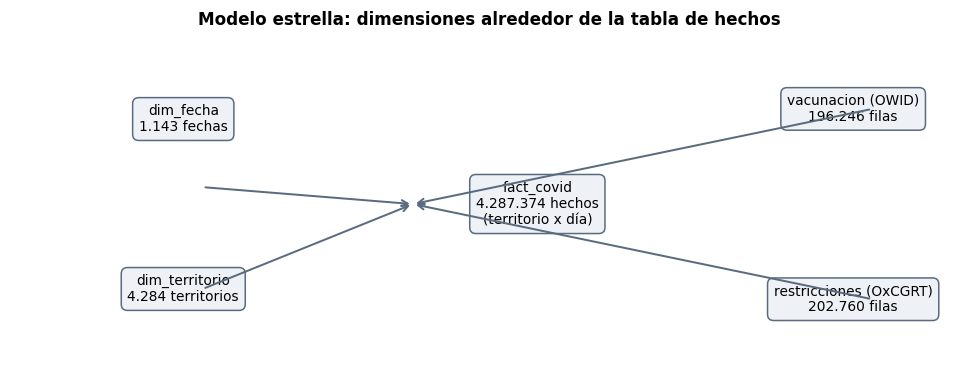

In [6]:
# --- Hito 2 · Esquema en estrella (esquema visual) -------------------------
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axis("off")
cajas = {
    "dim_fecha\n1.143 fechas": (0.18, 0.75),
    "dim_territorio\n4.284 territorios": (0.18, 0.25),
    "fact_covid\n4.287.374 hechos\n(territorio x día)": (0.55, 0.50),
    "vacunacion (OWID)\n196.246 filas": (0.88, 0.78),
    "restricciones (OxCGRT)\n202.760 filas": (0.88, 0.22),
}
for texto, (x, y) in cajas.items():
    ax.text(x, y, texto, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="#eef2f7", edgecolor="#5b6b7f"))
for origen, destino in [(0.18, 0.55), (0.18, 0.25), (0.88, 0.78), (0.88, 0.22)]:
    ax.annotate("", xy=(0.42, 0.50), xytext=(origen + 0.02, destino),
                arrowprops=dict(arrowstyle="->", color="#5b6b7f", lw=1.3))
ax.set_title("Modelo estrella: dimensiones alrededor de la tabla de hechos", fontsize=11, weight="bold")
fig.tight_layout()
plt.show()

### Hito 2 · 2.4 Calidad y gobernanza (R2)

La calidad **no** se corrige a ojo: se mide con reglas ejecutables en seis dimensiones (completitud, unicidad, validez, consistencia, exactitud y oportunidad). Cada regla tiene **umbral, valor medido, estado y decisión**; ninguna revisión de la fuente se borra: se **marca**.

In [7]:
# --- Hito 2 · Reglas de calidad ejecutables --------------------------------
from calidad import mediciones, reglas, indice_pais

med = mediciones(con)
tabla_reglas = pd.DataFrame(reglas(med)).rename(columns={
    "dimension": "Dimensión", "nombre": "Regla", "umbral": "Umbral",
    "valor": "Valor medido", "estado": "Estado", "decision": "Decisión"})
tabla_reglas["Estado"] = tabla_reglas["Estado"].map(
    {"ok": "Correcto", "warn": "Advertencia", "fail": "Falla"})
display(tabla_reglas[["Dimensión", "Regla", "Umbral", "Valor medido", "Estado", "Decisión"]]
        .style.set_caption("Reglas de calidad: 5 correctas · 10 advertencias · 1 falla"))

resumen = tabla_reglas["Estado"].value_counts().rename_axis("Estado").reset_index(name="Reglas")
display(resumen)

,Dimensión,Regla,Umbral,Valor medido,Estado,Decisión
0,completitud,cobertura_fechas,1.143/1.143 días con al menos un reporte,1143/1143,Correcto,"Ningún día sin reporte; si apareciera uno, se marcaría y se documentaría."
1,completitud,nulos_confirmed,0 nulos,28 (0.001 %),Advertencia,Se conservan los nulos; no se imputan. Revisar filas afectadas.
2,completitud,nulos_deaths,0 nulos,433 (0.01 %),Advertencia,Se conservan los nulos; no se imputan.
3,completitud,recovered_active_discontinuados,informativa: JHU dejó de publicarlos (desde 2021-03),recovered nulos 65.971 %; active nulos 66.189 %,Advertencia,No se usan como serie completa; se excluyen de P1–P7 y de modelos.
4,completitud,poblacion_territorios,>= 90 % de territorios con población,4019/4284 con población,Correcto,Los sin población (barcos/eventos y algunos territorios) no entran en tasas por 100.000.
5,unicidad,duplicados_territorio_fecha,0 tras consolidación (se conserva la fila de mayor acumulado),0,Correcto,99 pares mismo territorio/fecha (grafo de transición de nombres) fusionados conservando el max.
6,validez,acumulados_negativos,0 filas con confirmed/deaths/recovered < 0,7 filas,Falla,Errores del origen (correcciones publicadas como filas). Se conservan y se MARCAN; se excluyen de promedios y modelos; no se usan para diferenciar nuevos.
7,validez,lat_long_rango,"lat en [-90,90], long en [-180,180]",0 lat; 0 long,Correcto,Sin violaciones.
8,validez,poblacion_positiva,población > 0 cuando existe,0 violaciones,Correcto,Sin violaciones.
9,validez,cfr_sobre_100,0 (o explicar); aquí: valores extremos por bajas en testeo o correcciones,2001 filas,Advertencia,Se conservan; no se usan para comparar letalidad entre países sin advertencia.


,Estado,Reglas
0,Advertencia,10
1,Correcto,5
2,Falla,1


,País (ISO3),Índice de calidad,Retrocesos,Días con vacío > 7 d,Fallecidos > casos,Acumulados negativos,Letalidad > 100 %
61,USA,34.000000,54746,0,7125,3,1347
43,COL,64.100000,234,1,508,4,3
117,PER,65.800000,466,0,13,0,3
159,BEL,69.500000,18,0,348,0,348
179,PRK,70.000000,0,0,300,0,299
0,NLD,71.400000,300,0,64,0,1
173,CAN,78.700000,51,0,1039,0,0
145,GBR,79.300000,26,0,1377,0,0
193,DEU,88.000000,454,0,0,0,0
82,MEX,89.400000,390,1,0,0,0


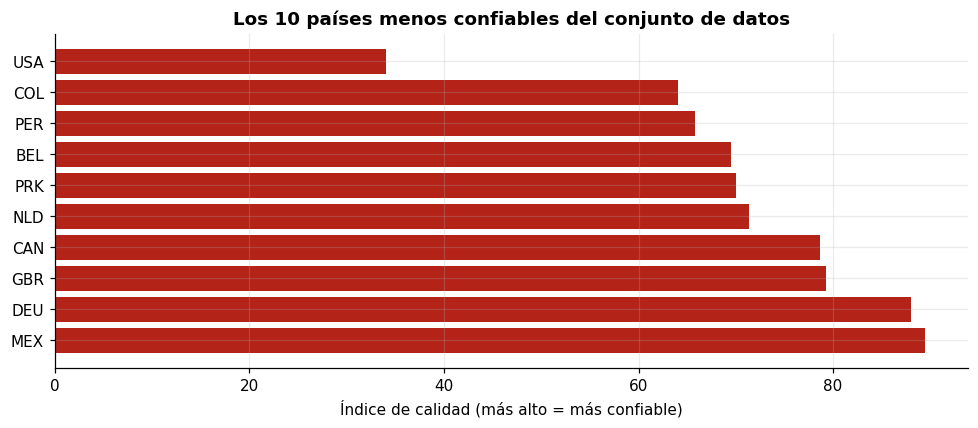

In [8]:
# --- Hito 2 · Índice de confiabilidad por país ------------------------------
idx = indice_pais(con).copy()
peores = (idx.nsmallest(10, "indice")
          .loc[:, ["pais_iso3", "indice", "retrocesos", "gaps_largos", "deaths_gt_confirmed",
                   "negativas", "cfr_100"]]
          .rename(columns={"pais_iso3": "País (ISO3)", "indice": "Índice de calidad",
                            "retrocesos": "Retrocesos", "gaps_largos": "Días con vacío > 7 d",
                            "deaths_gt_confirmed": "Fallecidos > casos",
                            "negativas": "Acumulados negativos", "cfr_100": "Letalidad > 100 %"}))
display(peores.style.set_caption("Los 10 países con peor índice de calidad (100 = sin problemas)"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(peores["País (ISO3)"], peores["Índice de calidad"], color="#b42318")
ax.set_xlabel("Índice de calidad (más alto = más confiable)")
ax.set_title("Los 10 países menos confiables del conjunto de datos", weight="bold")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

### Hito 2 · 2.5 Fuentes externas (OWID y OxCGRT)

Las dos fuentes externas se cruzan con JHU por **código ISO3**. Lo importante no es solo el porcentaje que cruza, sino **declarar los límites**: qué países no cruzan, por qué y qué se hace con ellos.

In [9]:
# --- Hito 2 · Cobertura de las fuentes externas -----------------------------
from analisis_restricciones import cobertura

restaurar_backend_interactivo()

cov = cobertura(con)
paises_jhu = cov["jhu_total"]

owid_paises = con.execute("""
    SELECT count(DISTINCT v.pais_iso3) FROM v_nacional_acum v
    WHERE v.pais_iso3 IN (
        SELECT DISTINCT iso3 FROM vacunacion
        WHERE iso3 IS NOT NULL AND NOT es_agregado)
""").fetchone()[0]
print(f"OWID (vacunación): {owid_paises} países de JHU con datos de vacunación")
print(f"OxCGRT (restricciones): {cov['paises']} países de origen, {cov['filas']:,} filas país-día, "
      f"del {cov['fmin'].date()} al {cov['fmax'].date()}")
print(f"OxCGRT cruza con {cov['cruz']}/{paises_jhu} países de JHU ({100 * cov['cruz'] / paises_jhu:.1f} %)")

cobertura_tabla = pd.DataFrame([
    {"Fuente externa": "Our World in Data (vacunación)", "Filas": "196.246",
     "Cruzan con JHU": f"{owid_paises}/{paises_jhu}",
     "Cobertura": f"{100 * owid_paises / paises_jhu:.1f} %",
     "Uso en el proyecto": "Pregunta P7 (vacunación vs mortalidad)"},
    {"Fuente externa": "Oxford OxCGRT (restricciones)", "Filas": f"{cov['filas']:,}",
     "Cruzan con JHU": f"{cov['cruz']}/{paises_jhu}",
     "Cobertura": f"{100 * cov['cruz'] / paises_jhu:.1f} %",
     "Uso en el proyecto": "Análisis extra: respuesta política frente a las olas"},
])
display(cobertura_tabla.style.set_caption("Cobertura de las fuentes externas (cruce por ISO3)"))
print("Países de JHU sin OxCGRT (muestra):", ", ".join(cov["jhu_sin"][:12]), "…")
print("Países de OxCGRT sin equivalente en JHU:", ", ".join(cov["sin_cruce"]))

OWID (vacunación): 201 países de JHU con datos de vacunación
OxCGRT (restricciones): 185 países de origen, 202,760 filas país-día, del 2020-01-01 al 2022-12-31
OxCGRT cruza con 182/218 países de JHU (83.5 %)


,Fuente externa,Filas,Cruzan con JHU,Cobertura,Uso en el proyecto
0,Our World in Data (vacunación),196.246,201/218,92.2 %,Pregunta P7 (vacunación vs mortalidad)
1,Oxford OxCGRT (restricciones),"202,760",182/218,83.5 %,Análisis extra: respuesta política frente a las olas


Países de JHU sin OxCGRT (muestra): ARM, ATA, ATG, BLM, COK, COM, CUW, CYM, FSM, GGY, GIB, GLP …
Países de OxCGRT sin equivalente en JHU: BMU, TKM, VIR


### Hito 2 · 2.6 Consultas OLAP sobre el almacén

Las preguntas del enunciado se resuelven **contra el DW** (roll-up, drill-down, slice y dice), nocontra los CSV sueltos. Estas son las cuatro operaciones, con el grano y la lógica a la vista.

In [10]:
# --- Hito 2 · Consultas OLAP de verificación --------------------------------
# ROLL-UP: del territorio al mundo, agregando por año.
rollup = con.execute("""
    SELECT d.anio AS "Año",
           sum(v.new_confirmed) AS "Nuevos casos",
           sum(v.new_deaths) AS "Nuevos fallecidos"
    FROM v_nacional_dia v JOIN dim_fecha d USING (fecha)
    WHERE v.pais_iso3 IS NOT NULL
    GROUP BY 1 ORDER BY 1
""").df()
display(rollup.style.set_caption("ROLL-UP — mundo por año (casos y fallecidos nuevos)"))

,Año,Nuevos casos,Nuevos fallecidos
0,2020,83762020.000000,1901692.000000
1,2021,204911743.000000,3566231.000000
2,2022,371621872.000000,1224558.000000
3,2023,16105439.000000,188428.000000


In [11]:
# DRILL-DOWN: de Chile nacional a cada región, en un año.
drill = con.execute("""
    SELECT region AS "Región",
           sum(new_confirmed) AS "Nuevos casos",
           sum(new_deaths) AS "Nuevos fallecidos",
           round(1e5 * sum(new_confirmed) / max(population), 1) AS "Casos por 100.000",
           round(1e5 * sum(new_deaths) / max(population), 1) AS "Fallecidos por 100.000"
    FROM vl_chile_regiones
    WHERE fecha >= DATE '2021-01-01' AND fecha < DATE '2022-01-01'
    GROUP BY 1 ORDER BY 5 DESC NULLS LAST
""").df()
display(drill.head(8).style.set_caption("DRILL-DOWN — Chile 2021 por región (ordenado por mortalidad)"))

,Región,Nuevos casos,Nuevos fallecidos,Casos por 100.000,Fallecidos por 100.000
0,"Magallanes, Chile",13324.000000,275.000000,8000.800000,165.100000
1,"Tarapaca, Chile",29432.000000,545.000000,8903.700000,164.900000
2,"Los Rios, Chile",44987.000000,634.000000,11689.900000,164.700000
3,"Los Lagos, Chile",73566.000000,1247.000000,8877.200000,150.500000
4,"Arica y Parinacota, Chile",18161.000000,321.000000,8033.400000,142.000000
5,"Biobio, Chile",120371.000000,2045.000000,7731.900000,131.400000
6,"Valparaiso, Chile",102541.000000,2380.000000,5646.800000,131.100000
7,"Araucania, Chile",81222.000000,1254.000000,8485.200000,131.000000


In [12]:
# SLICE y DICE: un año y cuatro países, con y sin filtro de fecha.
dice = con.execute("""
    SELECT v.pais_iso3 AS "País (ISO3)",
           sum(v.new_confirmed) AS "Nuevos casos (2021)",
           sum(v.new_deaths) AS "Nuevos fallecidos (2021)",
           round(1e5 * max(v.confirmed) / max(v.poblacion), 1) AS "Acumulados por 100.000"
    FROM v_nacional_dia v
    WHERE v.pais_iso3 IN ('CHL', 'PER', 'USA', 'BRA')
      AND v.fecha >= DATE '2021-01-01' AND v.fecha < DATE '2022-01-01'
    GROUP BY 1 ORDER BY 2 DESC
""").df()
display(dice.style.set_caption("DICE — Chile, Perú, EE.UU. y Brasil, año 2021"))

,País (ISO3),Nuevos casos (2021),Nuevos fallecidos (2021),Acumulados por 100.000
0,USA,34675558.000000,474715.000000,16659.700000
1,BRA,14610807.000000,424262.000000,10487.300000
2,PER,1281694.000000,109620.000000,6966.000000
3,CHL,1197521.000000,22507.000000,9450.100000


---

# Cierre — Estado del Hito 2

| Entregable del Hito 2 | Evidencia en este notebook | Estado |
|---|---|---|
| Descarga automatizada y datos crudos versionados aparte | Sección 0 (estado de las capas) | ✔ |
| Unificación de los cinco esquemas de JHU con `etapa_esquema` | Sección 1 (etapas de esquema) | ✔ |
| Capa limpia en Parquet (filas, tamaño y compression) | Sección 1 | ✔ |
| Identidad territorial con cruce contra la UID | Sección 2 | ✔ |
| Almacén en estrella con grano declarado y controles | Sección 3 | ✔ |
| Reglas de calidad ejecutables (6 dimensiones) e índice por país | Sección 4 | ✔ |
| Integración de OWID y OxCGRT por ISO3, con cobertura y límites | Sección 5 | ✔ |
| Consultas OLAP (roll-up, drill-down, slice, dice) sobre el DW | Sección 6 | ✔ |

**Lo que viene después:** el Hito 3 (`Hito 3.ipynb`) usa este almacén para responder P1–P7, evaluar modelos y construir el tablero.

In [13]:
# --- Verificación del Hito 2 ------------------------------------------------
verificaciones = [
    ("Capas del proyecto disponibles", f"{int((capas['Estado'] == 'Disponible').sum())}/3",
     (capas["Estado"] == "Disponible").all()),
    ("Etapas de esquema unificadas", f"{len(etapas)} etapas", len(etapas) == 5),
    ("Tablas del almacén disponibles", f"{len(inventario_es)} objetos", len(inventario_es) >= 6),
    ("Sin duplicados ni fechas huérfanas",
     f"{int(controles.iloc[0, 0])} duplicados · {int(controles.iloc[0, 1])} huérfanas",
     bool(controles.iloc[0, 0] == 0 and controles.iloc[0, 1] == 0)),
    ("Reglas de calidad evaluadas", f"{len(tabla_reglas)} reglas", len(tabla_reglas) >= 15),
    ("Territorios con ISO3 para cruzar fuentes externas",
     f"{con_iso3:,} de {len(territorios):,}", con_iso3 > 4000),
    ("Fuentes externas cruzadas por ISO3",
     f"OWID {owid_paises}/{paises_jhu} · OxCGRT {cov['cruz']}/{paises_jhu}",
     owid_paises > 190 and cov["cruz"] > 170),
    ("Consultas OLAP ejecutadas", f"{len(rollup) + len(drill) + len(dice)} filas devueltas",
     len(rollup) > 0 and len(drill) > 0 and len(dice) == 4),
]
resumen_hito2 = pd.DataFrame(verificaciones, columns=["Verificación", "Resultado", "Estado"])
resumen_hito2["Estado"] = resumen_hito2["Estado"].map({True: "OK", False: "REVISAR"})
display(resumen_hito2.style.set_caption("Verificación del Hito 2"))
print("El Hito 2 se ejecuta de principio a fin sin errores.")

,Verificación,Resultado,Estado
0,Capas del proyecto disponibles,3/3,OK
1,Etapas de esquema unificadas,5 etapas,OK
2,Tablas del almacén disponibles,9 objetos,OK
3,Sin duplicados ni fechas huérfanas,0 duplicados · 0 huérfanas,OK
4,Reglas de calidad evaluadas,16 reglas,OK
5,Territorios con ISO3 para cruzar fuentes externas,"4,401 de 4,410",OK
6,Fuentes externas cruzadas por ISO3,OWID 201/218 · OxCGRT 182/218,OK
7,Consultas OLAP ejecutadas,25 filas devueltas,OK


El Hito 2 se ejecuta de principio a fin sin errores.
